# Compare network predictions from TPS, TimeXNet, and Dynamic Bayesian Network - June 7, 2016
Similar to the June 1, 2016 version but saved the Venn diagram figures.  Also adds a comparison to TPS run on the directed TXN output and a comparison between the predicted networks and the EGFR reference pathway nodes.

## Initializations

In [1]:
%pylab inline
import os
from collections import defaultdict
import pyupset as pyu
import pandas as pd
from matplotlib_venn import venn2_unweighted, venn3_unweighted

tps_dir = os.path.join('..','..','synthesis072614')
tps_file = os.path.join(tps_dir,'p-0.01_202dir_cytoscape_genes_092515.txt')

# Same TXN network is in the 2016-05-03-DBN-TXN-TPS-networks directory
txn_file = os.path.join('..','..','TimeXNet','results','020916','net_4.5_0.0','lp_sol_4.5-0.0_nw.sif')
# The same network as tps_file, used solely to verify the parsing is correct
txn_alt_file = os.path.join('..','..','evaluation','2016-05-03-DBN-TXN-TPS-networks','TXN-ALL-directed.sif')

dbn_file = os.path.join('..','..','evaluation','2016-05-03-DBN-TXN-TPS-networks','DBN.tsv')
txn_tps_file = os.path.join('..','..','evaluation','2016-05-03-DBN-TXN-TPS-networks','TXN-ALL-undirected-topo-kinsub-temporal-output.sif')
# Used to assess how TPS temporal constraints detect violations in TXN temporal constraints
txn_tps_dir_file = os.path.join('..','..','evaluation','2016-05-03-DBN-TXN-TPS-networks','TXN-ALL-directed-topo-kinsub-temporal-output.sif')

# EGFR reference pathway nodes
gold_standard_file = os.path.join('..','..','evaluation','2014-10-03','eight-egfr-reference-all.txt')

out_dir = os.path.join('..','..','evaluation','2016-06-07-network-overlaps')

Populating the interactive namespace from numpy and matplotlib


## Load the EGFR reference pathway nodes

In [2]:
gs_df = pd.read_csv(gold_standard_file, header=None, names=['Nodes'])
print 'Loaded %d EGFR reference pathway nodes' % len(gs_df)
gs_df.head()

Loaded 324 EGFR reference pathway nodes


,Nodes
0,1433B_HUMAN
1,1433E_HUMAN
2,1433T_HUMAN
3,4EBP1_HUMAN
4,ABI1_HUMAN


## Helper functions to load the networks
Track directed and undirected edges separately so that they are recognized as different types of predictions.  Use :u: to separate proteins in an undirected edge and :d: for directed edges (signs are ignored).  When creating an undirected edge, sort the protein names.  The node helper function takes the list of edges in a data frame, creates a set of the unique nodes in those edges, and returns a new data frame listing those nodes.

### TPS
Expect 413 edges and 311 nodes.
- Activation, Inhibition, Unknown are directed edges
- None is an undirected edge

### TimeXNet
1073 edges and 626 nodes.  All are treated as directed edges because TimeXNet paper uses the flow direction during the evaluation.  TimeXNet node list has a bug, missing TXD11_HUMAN.
- pp indicates undirected edge in the input PPI network
- pd indicates directed edge in the input PPI network

### Dynamic Bayesian Network (DBN)
Use the PPI prior, max in-degree of 2 version of the network.  1138084 peptide-peptide interactions because self-edges have been removed already.  All peptide-peptide interactions are directed.  Store protein-protein edges by taking the max probability over all corresponding peptide-peptide edges.  here are 490700 = 701^2-701 directed protein-protein edges.  Ignore edge sign.

### TimeXNet+TPS
Strips the TimeXNet network of its directions and does not filter based on edge flow to obtain a seed network.  Then runs TPS on the undirected TimeXNet-based seed network.  After running TPS, the network has 1063 edges and 622 nodes.

### TimeXNet(directed)+TPS
Retains the TimeXNet flow-based directions and does not filter based on edge flow to obtain a seed network.  Then runs TPS on the directed TimeXNet-based seed network to detect conflicts between the TimeXNet and TPS temporal constraints.  After running TPS, the network has 725 edges and 449 nodes.

In [3]:
# This parser is for older TPS files
def load_tps(tps_file):
    # Create a list of edges
    edges = list()
    dir_count = 0
    undir_count = 0
    
    with open(tps_file) as tps_f:
        for line in tps_f:
            # Prot1 \t Prot2 \t EdgeType
            parts = line.strip().split('\t')
            if parts[2] == 'Activation' or parts[2] == 'Inhibition' or parts[2] == 'Unknown':
                # Add directed edge in the correct direction
                edges.append('%s:d:%s' % (parts[0], parts[1]))
                dir_count += 1
            elif parts[2] == 'None':
                # Sort the nodes in an undirected edge
                sorted_prots = sorted((parts[0], parts[1]))
                edges.append('%s:u:%s' % (sorted_prots[0], sorted_prots[1]))
                undir_count += 1
            else:
                raise RuntimeError('Invalid edge type')
    
    # Create a data frame
    df = pd.DataFrame(data=edges, columns=['Edges'])
    print 'Loaded %d edges from TPS network, %d directed and %d undirected' % (len(df), dir_count, undir_count)
    return df


def load_txn(txn_file):
    # Create a list of edges
    dir_edges = list()
    pd_count = 0
    
    with open(txn_file) as txn_f:
        for line in txn_f:
            # Prot1 \t EdgeType \t Prot2
            parts = line.strip().split('\t')
            assert parts[1] == 'pp' or parts[1] == 'pd', 'Expected pp or pd'
            # Regardless of whether the edge was originally directed or undirected, use the flow direction
            # as the predicted direction
            dir_edges.append('%s:d:%s' % (parts[0], parts[2]))
            if parts[1] == 'pd':
                pd_count += 1
    
    # Create a data frame
    df = pd.DataFrame(data=dir_edges, columns=['Edges'])
    print 'Loaded %d directed edges from TimeXNet network, %d directions from PPI network' % (len(df), pd_count)
    return df


def load_dbn(dbn_file):
    # Create a mapping of directed protein-protein edges to their max probability
    dir_edges = defaultdict(float)
    self_count = 0
    
    with open(dbn_file) as dbn_f:
        # Skip the header
        dbn_f.readline()
        for line in dbn_f:
            # protein 1 \t protein 2 \t probability \t sign \t peptide 1 \t peptide 2
            parts = line.strip().split('\t')
            # Ignore self-edges, which occur when a multiple peptides map to a protein
            if (not parts[0] == parts[1]):
                edge = '%s:d:%s' % (parts[0], parts[1])
                dir_edges[edge] = max(dir_edges[edge], float(parts[2]))
            else:
                self_count +=1 
        
    # Create a data frame
    df = pd.DataFrame(data=dir_edges.items(), columns=['Edges', 'Probabilities'])
    print 'Loaded %d directed edges from Dynamic Bayesian Network, ignored %d self-edges' % (len(df), self_count)
    return df


# This is the appropriate parser for the current TPS file format
def load_txn_tps(tps_file):
    # Create a list of edges
    edges = list()
    dir_count = 0
    undir_count = 0
    
    with open(tps_file) as tps_f:
        for line in tps_f:
            # Prot1 \t EdgeType \t Prot2
            parts = line.strip().split('\t')
            # N and U are different than in the load_tps file.  Here U is undirected and N is none for a
            # directed edge with no edge sign.
            if parts[1] == 'A' or parts[1] == 'I' or parts[1] == 'N':
                # Add directed edge in the correct direction
                edges.append('%s:d:%s' % (parts[0], parts[2]))
                dir_count += 1
            elif parts[1] == 'U':
                # Sort the nodes in an undirected edge
                sorted_prots = sorted((parts[0], parts[2]))
                edges.append('%s:u:%s' % (sorted_prots[0], sorted_prots[1]))
                undir_count += 1
            else:
                raise RuntimeError('Invalid edge type')
    
    # Create a data frame
    df = pd.DataFrame(data=edges, columns=['Edges'])
    print 'Loaded %d edges from TimeXNet + TPS network, %d directed and %d undirected' % (len(df), dir_count, undir_count)
    return df


def extract_nodes(edge_df):
    node_set = set()
    for edge in edge_df['Edges']:
        parts = edge.split(':')
        assert len(parts) == 3, 'Expected two nodes and interaction type'
        assert parts[1] == 'u' or parts[1] == 'd', 'Expected directed or undirected edge'
        node_set.add(parts[0])
        node_set.add(parts[2])

    print 'Loaded %d nodes' % len(node_set)
    
    # Create a new data frame
    return pd.DataFrame(data=list(node_set), columns=['Nodes'])

## Load the TPS, TimeXNet, DBN, and TimeXNet+TPS networks
Set a DBN probability threshold of >= 0.025, which Ali used to produce a DBN network that is comparable in size to the TPS network (453 nodes).  Store a list of all proteins in the mass spec data, including the PSEUDONODE.

In [4]:
tps_df = load_tps(tps_file)
tps_node_df = extract_nodes(tps_df)
print

txn_df = load_txn(txn_file)
txn_node_df = extract_nodes(txn_df)
print

dbn_thresh = 0.025
dbn_df = load_dbn(dbn_file)
dbn_thresh_df = dbn_df[dbn_df['Probabilities'] >= dbn_thresh]
print '%d DBN edges with probability >= %s' % (len(dbn_thresh_df), str(dbn_thresh))
dbn_thresh_node_df = extract_nodes(dbn_thresh_df)
print

print 'Undirected TimeXNet seed'
txn_tps_df = load_txn_tps(txn_tps_file)
txn_tps_node_df = extract_nodes(txn_tps_df)
print

print 'Directed TimeXNet seed'
txn_tps_dir_df = load_txn_tps(txn_tps_dir_file)
txn_tps_dir_node_df = extract_nodes(txn_tps_dir_df)
print

# The complete DBN network without a threshold can be used to obtain the list of all phosphorylated proteins in the mass spec data
print 'Store list of all proteins in mass spectrometry dataset'
ms_node_df = extract_nodes(dbn_df)

Loaded 413 edges from TPS network, 202 directed and 211 undirected
Loaded 311 nodes

Loaded 1073 directed edges from TimeXNet network, 178 directions from PPI network
Loaded 626 nodes

Loaded 490700 directed edges from Dynamic Bayesian Network, ignored 0 self-edges
587 DBN edges with probability >= 0.025
Loaded 453 nodes

Undirected TimeXNet seed
Loaded 1063 edges from TimeXNet + TPS network, 300 directed and 763 undirected
Loaded 622 nodes

Directed TimeXNet seed
Loaded 725 edges from TimeXNet + TPS network, 725 directed and 0 undirected
Loaded 449 nodes

Store list of all proteins in mass spectrometry dataset
Loaded 701 nodes


## Load the TimeXNet network again
Verify the parser works by loading the same network in a different format and checked the intersection

Loaded 1073 edges from TimeXNet + TPS network, 1073 directed and 0 undirected
Loaded 626 nodes


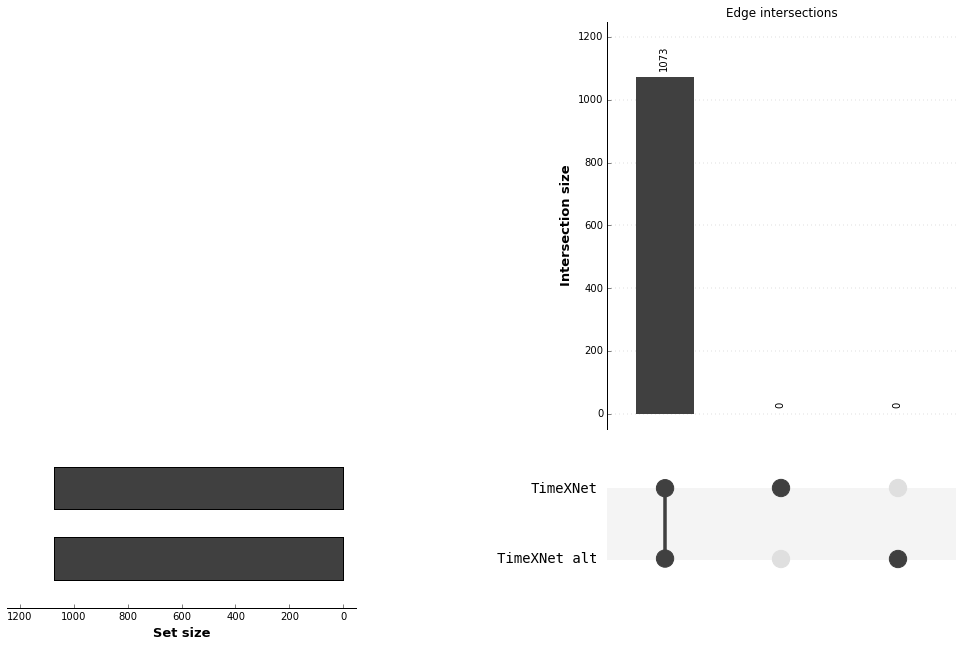

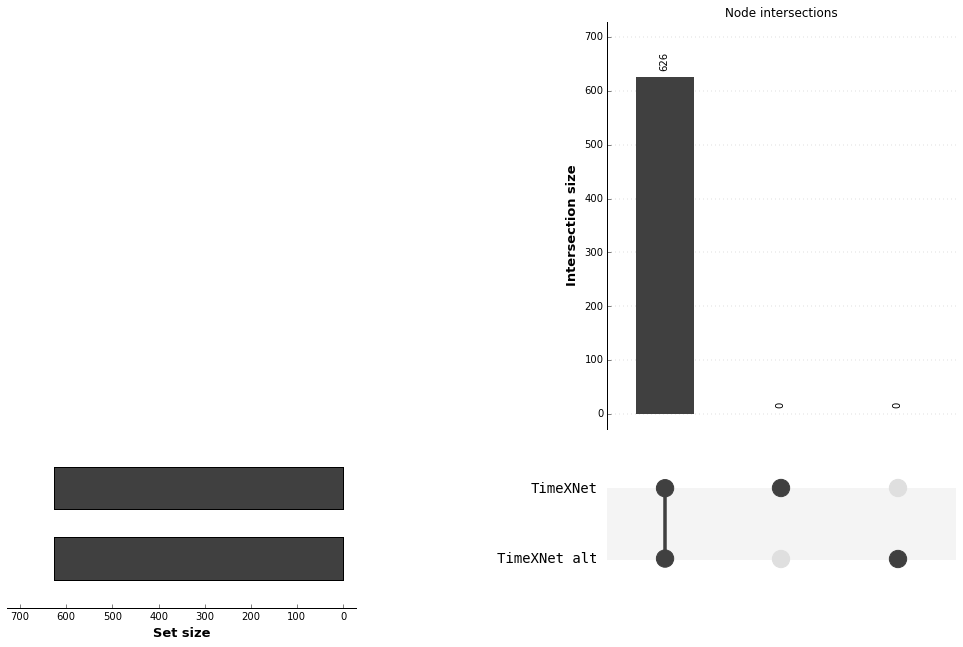

In [5]:
txn_alt_df = load_txn_tps(txn_alt_file)
txn_alt_node_df = extract_nodes(txn_alt_df)

pyu.plot({'TimeXNet':txn_df, 'TimeXNet alt':txn_alt_df});
title('Edge intersections');

pyu.plot({'TimeXNet':txn_node_df, 'TimeXNet alt':txn_alt_node_df});
title('Node intersections');

## Wrapper function for Venn diagrams
Take the same arguments as pyUpSet and return them in a format that can be directly fed to matplotlib-venn

In [6]:
def venn_wrapper(df_dict, col):
    set_list = []
    label_list = []
    for label, df in df_dict.items():
        label_list.append(label)
        set_list.append(set(df[col]))
    
    return set_list, label_list

## Visualize the intersection between the TPS, TimeXNet, and DBN networks
Compare edges and nodes.

Recall that directed and undirected nodes are not equivalent and will not match during the intersection computation.  Use pyUpSet and traditional Venn diagrams to assess the two visualization options.

The edge intersections reveal that the majority of edges from each method are unique to that method.  This is accentuated because all of the TPS undirected edges will not match the TimeXNet and DBN directed edges.  However, even TimeXNet and DBN, which only make directed predictions, only agree on 14 edges.  We can't argue that any method is better than the other from this analysis.  **But the different algorithms clearly reason with temporal data in very different ways.**  The node intersections are more similar, but even those are fairly disjoint.  TimeXNet (without a flow filter here) makes more predictions than the others so naturally it has more unique nodes.

109 proteins (potentially including one pseudonode) that are observed in the mass spectrometry do not appear in any of the predicted networks.  This may be reasonable because not all of those proteins have substantial changes in their phosphorylation levels.  DBN can only predict phosphorylated nodes but the other methods can include other intermediate nodes.

Save the Venn diagram images.

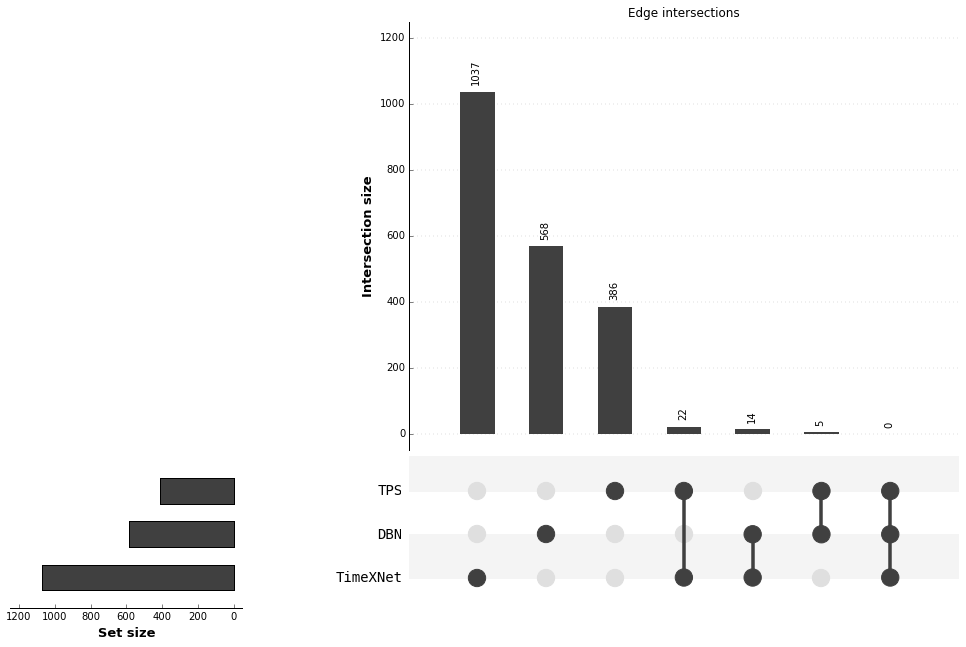

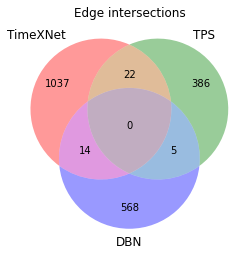

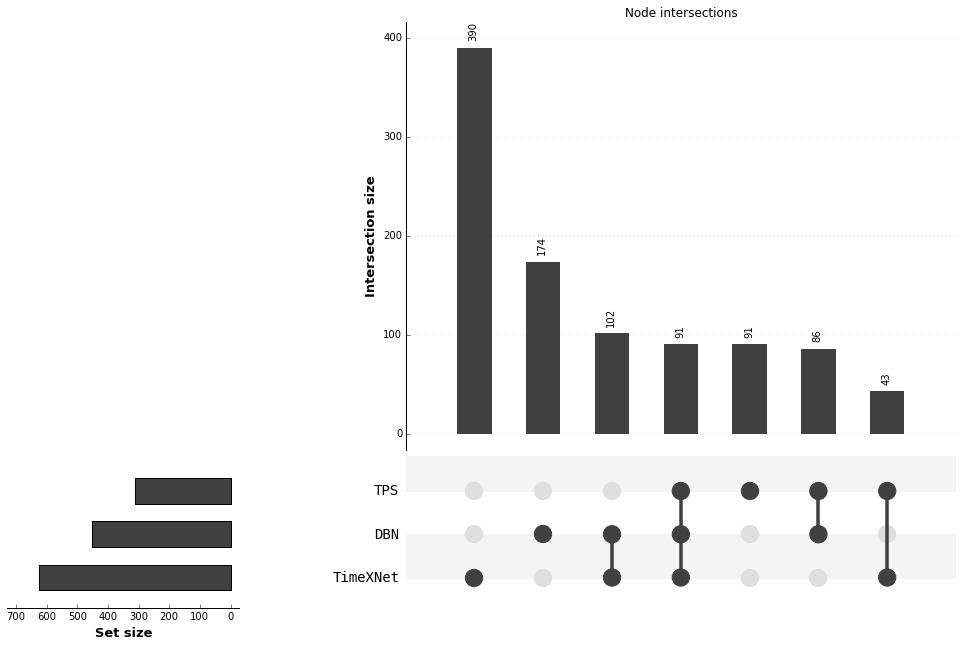

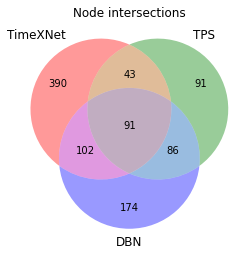

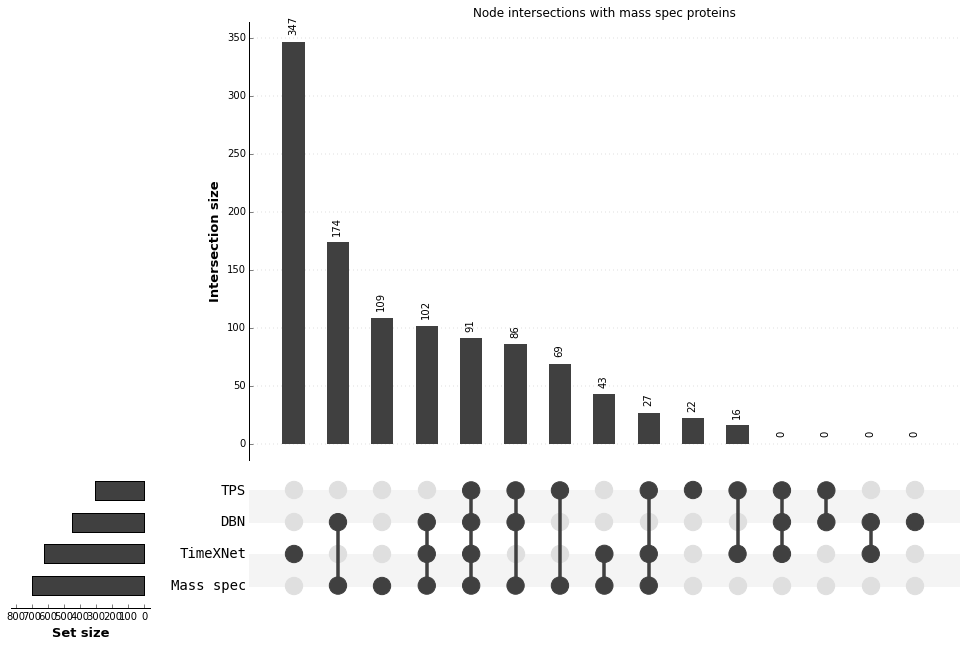

In [7]:
pyu.plot({'TPS':tps_df, 'TimeXNet':txn_df, 'DBN':dbn_thresh_df});
title('Edge intersections');

figure();
title('Edge intersections');
venn3_unweighted(*venn_wrapper({'TPS':tps_df, 'TimeXNet':txn_df, 'DBN':dbn_thresh_df}, 'Edges'))
savefig(os.path.join(out_dir, 'network-edge-overlap.png'), dpi=600, bbox_inches='tight')
savefig(os.path.join(out_dir, 'network-edge-overlap.svg'), bbox_inches='tight')
show()

pyu.plot({'TPS':tps_node_df, 'TimeXNet':txn_node_df, 'DBN':dbn_thresh_node_df});
title('Node intersections');

figure();
title('Node intersections');
venn3_unweighted(*venn_wrapper({'TPS':tps_node_df, 'TimeXNet':txn_node_df, 'DBN':dbn_thresh_node_df}, 'Nodes'))
savefig(os.path.join(out_dir, 'network-node-overlap.png'), dpi=600, bbox_inches='tight')
savefig(os.path.join(out_dir, 'network-node-overlap.svg'), bbox_inches='tight')
show()

pyu.plot({'TPS':tps_node_df, 'TimeXNet':txn_node_df, 'DBN':dbn_thresh_node_df, 'Mass spec':ms_node_df});
title('Node intersections with mass spec proteins');

## Compare TimeXNet versus TimeXNet(undirected)+TPS network
Assess TPS run on the undirected TimeXNet seed.  All of the edges that TPS leaves undirected will not overlap with the original TimeXNet network, which directs all edges.  TimeXNet+TPS had 300 directed edges so 14 of those directions disagree with the original TimeXNet direction.

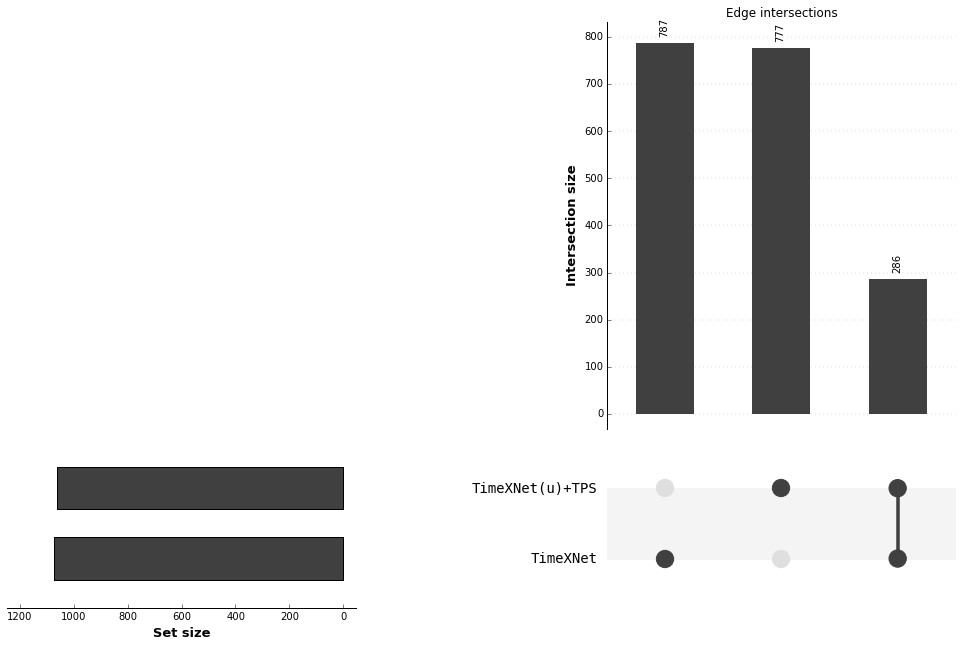

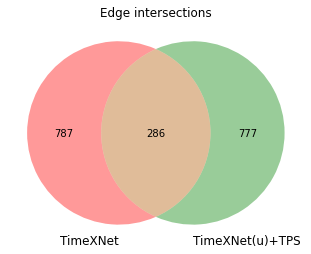

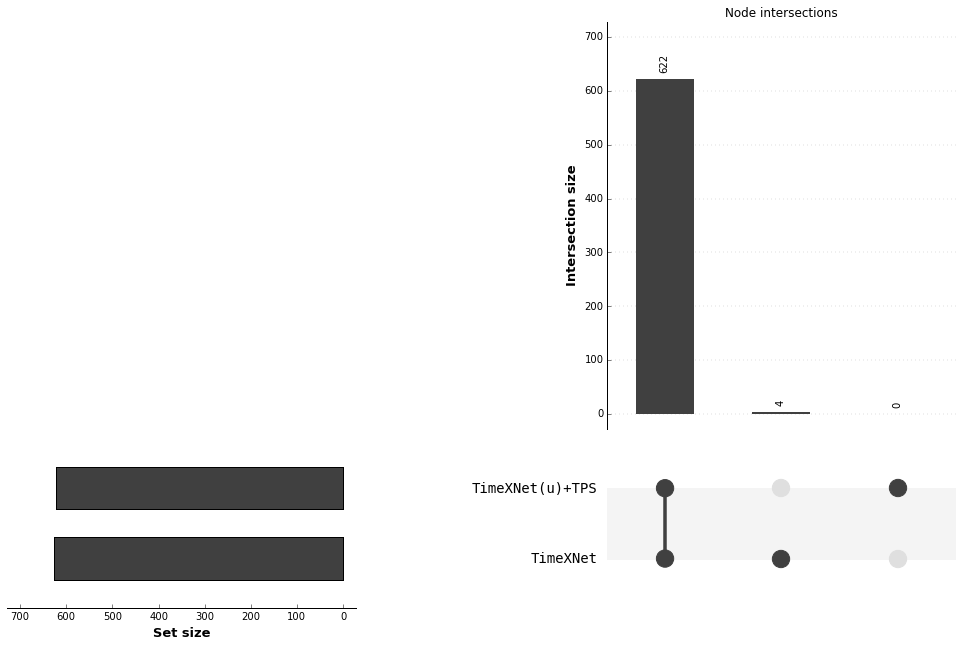

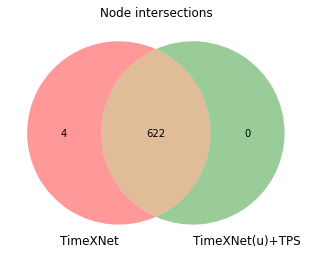

In [8]:
pyu.plot({'TimeXNet':txn_df, 'TimeXNet(u)+TPS':txn_tps_df});
title('Edge intersections');

figure();
title('Edge intersections');
venn2_unweighted(*venn_wrapper({'TimeXNet':txn_df, 'TimeXNet(u)+TPS':txn_tps_df}, 'Edges'))
show()

pyu.plot({'TimeXNet':txn_node_df, 'TimeXNet(u)+TPS':txn_tps_node_df});
title('Node intersections');

figure();
title('Node intersections');
venn2_unweighted(*venn_wrapper({'TimeXNet':txn_node_df, 'TimeXNet(u)+TPS':txn_tps_node_df}, 'Nodes'))
show()

## Compare TimeXNet versus TimeXNet(directed)+TPS network
Assess TPS run on the directed TimeXNet seed.  All of the edges in the network will still be directed, and TPS removes 348 edges that violate its temporal or topological constraints.  177 nodes are completely removed as a consequence of the filtered edges.

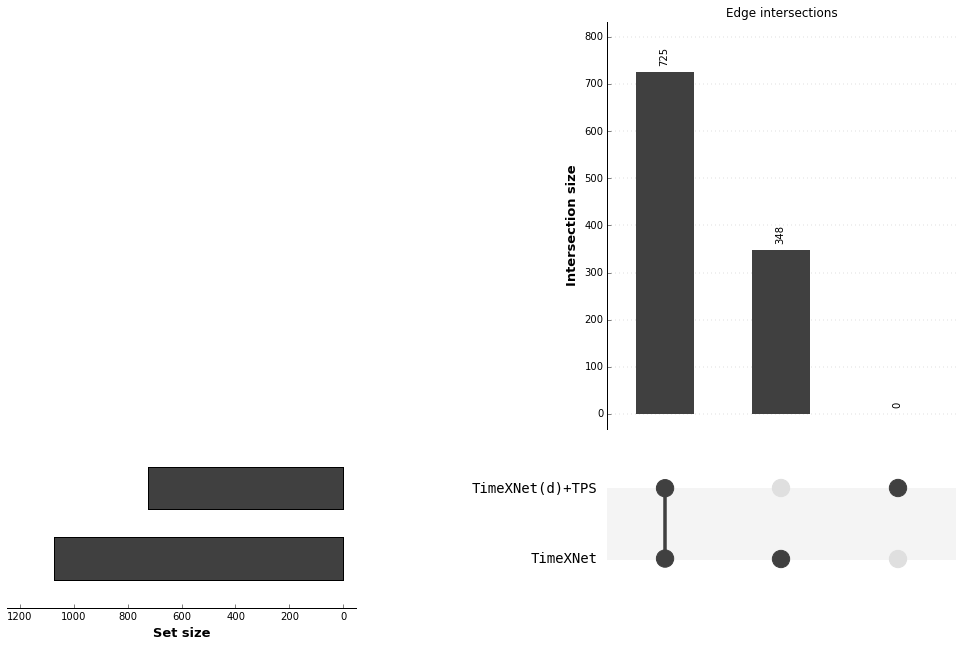

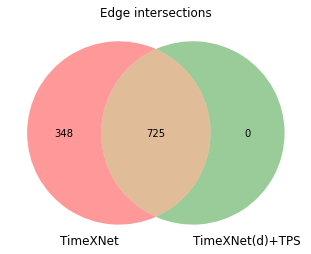

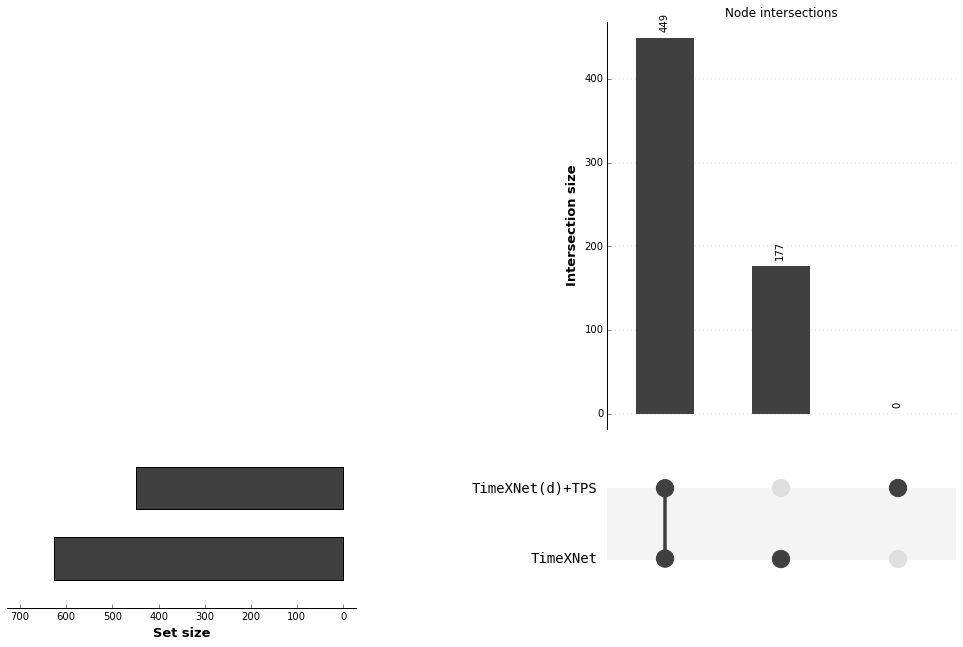

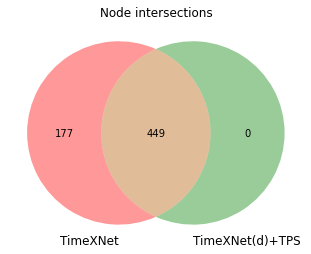

In [9]:
pyu.plot({'TimeXNet':txn_df, 'TimeXNet(d)+TPS':txn_tps_dir_df});
title('Edge intersections');

figure();
title('Edge intersections');
venn2_unweighted(*venn_wrapper({'TimeXNet':txn_df, 'TimeXNet(d)+TPS':txn_tps_dir_df}, 'Edges'))
show()

pyu.plot({'TimeXNet':txn_node_df, 'TimeXNet(d)+TPS':txn_tps_dir_node_df});
title('Node intersections');

figure();
title('Node intersections');
venn2_unweighted(*venn_wrapper({'TimeXNet':txn_node_df, 'TimeXNet(d)+TPS':txn_tps_dir_node_df}, 'Nodes'))
show()

## Extract the nodes and edges that TPS removes from the undirected TimeXNet seed network
TPS removes 4 nodes and 10 edges from the TimeXNet seed network.  MK03_HUMAN is an important node in the EGFR pathway, so it could be argued that the TimeXNet seed does not contain sufficient edges to allow TPS to find an explanation for its activation.  This may be worth exploring further.  This edge comparison ignores edge direction, unlike the set-based comparisons elsewhere.  We have discussed the LCK_HUMAN -> CBL_HUMAN edge previously in the directed TimeXNet seed network.

In [10]:
# Helper function to extract undirected node pairs
def extract_node_pairs(edge_df):
    node_pair_set = set()
    for edge in edge_df['Edges']:
        parts = edge.split(':')
        assert len(parts) == 3, 'Expected two nodes and interaction type'
        assert parts[1] == 'u' or parts[1] == 'd', 'Expected directed or undirected edge'
        sorted_prots = sorted((parts[0], parts[2]))
        node_pair_set.add('%s:%s' % (sorted_prots[0], sorted_prots[1]))

    print 'Loaded %d node pairs' % len(node_pair_set)
    return node_pair_set

print 'TPS removes the following nodes from the undirected TimeXNet seed network:'
removed = set(txn_node_df.loc[~txn_node_df.isin(set(txn_tps_node_df['Nodes']))['Nodes']]['Nodes'].values)
print '\t'.join(sorted(removed))
print

removed_gs = removed.intersection(gs_df['Nodes'])
print 'TPS removes %d EGFR reference pathway node from the undirected TimeXNet seed network:' % len(removed_gs)
print '\t'.join(sorted(removed_gs))
print

txn_tps_node_pairs = extract_node_pairs(txn_tps_df)
print 'Edges TPS removes the following edges from the undirected TimeXNet seed network:'
for edge in txn_df['Edges']:
    parts = edge.split(':')
    assert len(parts) == 3, 'Expected two nodes and interaction type'
    assert parts[1] == 'u' or parts[1] == 'd', 'Expected directed or undirected edge'
    sorted_prots = sorted((parts[0], parts[2]))
    node_pair = '%s:%s' % (sorted_prots[0], sorted_prots[1])
    
    # Check if the node pair matches, ignoring edge direction
    if not node_pair in txn_tps_node_pairs:
        print '\t%s' % edge

TPS removes the following nodes from the undirected TimeXNet seed network:
MK03_HUMAN	NP1L1_HUMAN	NUP50_HUMAN	Q7Z5W8_HUMAN

TPS removes 1 EGFR reference pathway node from the undirected TimeXNet seed network:
MK03_HUMAN

Loaded 1063 node pairs
Edges TPS removes the following edges from the undirected TimeXNet seed network:
	NUP50_HUMAN:d:SRPK2_HUMAN
	MK03_HUMAN:d:NUP50_HUMAN
	NUP50_HUMAN:d:Q7Z5W8_HUMAN
	LCK_HUMAN:d:CBL_HUMAN
	EP300_HUMAN:d:NP1L1_HUMAN
	MK03_HUMAN:d:LCK_HUMAN
	MK03_HUMAN:d:STA5A_HUMAN
	NUP50_HUMAN:d:LMNA_HUMAN
	OSBP1_HUMAN:d:NP1L1_HUMAN
	MK01_HUMAN:d:NUP50_HUMAN


## Extract the nodes that TPS removes from the directed TimeXNet seed network
TPS removes 177 nodes and 348 edges from the TimeXNet seed network.  Do not list all of the edges because there are so many.  37 of these removed nodes happen to be EGFR reference pathway members.

In [11]:
print 'TPS removes the following nodes from the directed TimeXNet seed network:'
removed = set(txn_node_df.loc[~txn_node_df.isin(set(txn_tps_dir_node_df['Nodes']))['Nodes']]['Nodes'].values)
print '\t'.join(sorted(removed))
print

removed_gs = removed.intersection(gs_df['Nodes'])
print 'TPS removes %d EGFR reference pathway nodes from the directed TimeXNet seed network:' % len(removed_gs)
print '\t'.join(sorted(removed_gs))

TPS removes the following nodes from the directed TimeXNet seed network:
1433B_HUMAN	1433S_HUMAN	1433T_HUMAN	1433Z_HUMAN	41_HUMAN	A4D1G0_HUMAN	A4D2P1_HUMAN	A4QPA9_HUMAN	A8K7B7_HUMAN	A8KAH9_HUMAN	ABI2_HUMAN	ABL1_HUMAN	ACK1_HUMAN	ACTN1_HUMAN	ACTN4_HUMAN	AFAD_HUMAN	AKA10_HUMAN	AKAP5_HUMAN	ARHG5_HUMAN	ARL6_HUMAN	ARMX3_HUMAN	B2R5T5_HUMAN	B3KUN1_HUMAN	B4DTL2_HUMAN	B5B2P4_HUMAN	BBS1_HUMAN	BCAR1_HUMAN	BCR_HUMAN	CASL_HUMAN	CBLB_HUMAN	CBL_HUMAN	CBP_HUMAN	CD2A2_HUMAN	CD2AP_HUMAN	CDK5_HUMAN	CLASR_HUMAN	CLH1_HUMAN	CRCM_HUMAN	CRKL_HUMAN	CTNA1_HUMAN	CTR9_HUMAN	DDX21_HUMAN	DDX3X_HUMAN	DDX58_HUMAN	DESP_HUMAN	DOCK1_HUMAN	E9KL35_HUMAN	EF1A1_HUMAN	EP15R_HUMAN	EPOR_HUMAN	ERBB2_HUMAN	ERF_HUMAN	FAK2_HUMAN	FLNC_HUMAN	FYN_HUMAN	GAB1_HUMAN	GAB2_HUMAN	GPN1_HUMAN	GRAP2_HUMAN	GRB2_HUMAN	H2AY_HUMAN	HDAC3_HUMAN	HDAC6_HUMAN	HNRL1_HUMAN	IF4E2_HUMAN	IF4E_HUMAN	IGBP1_HUMAN	IGF1R_HUMAN	IKKE_HUMAN	IRF3_HUMAN	IRS1_HUMAN	IRS4_HUMAN	K1C15_HUMAN	K1C20_HUMAN	KAP2_HUMAN	KAPCB_HUMAN	KHDR1_HUMAN	KPCI_HUMAN	L7RRS6_HUMAN	L7RT18_HUM

## Visualize the intersection between the TPS, TimeXNet, DBN, and TimeXNet + TPS networks
Compare edges and nodes.  Recall that directed and undirected nodes are not equivalent and will not match during the intersection computation.  Uses the undirected seed for TimeXNet + TPS.

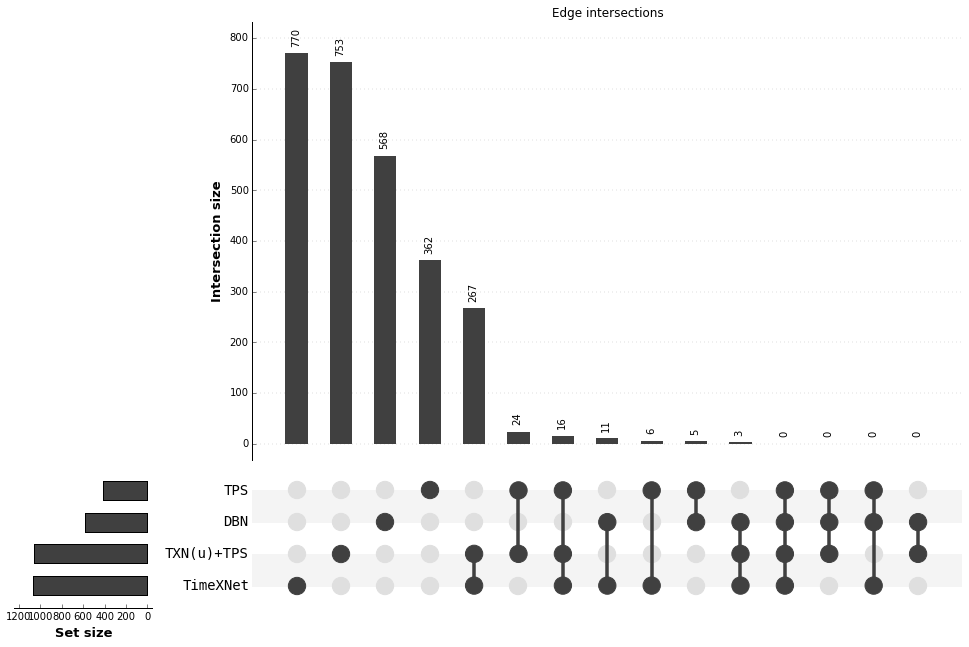

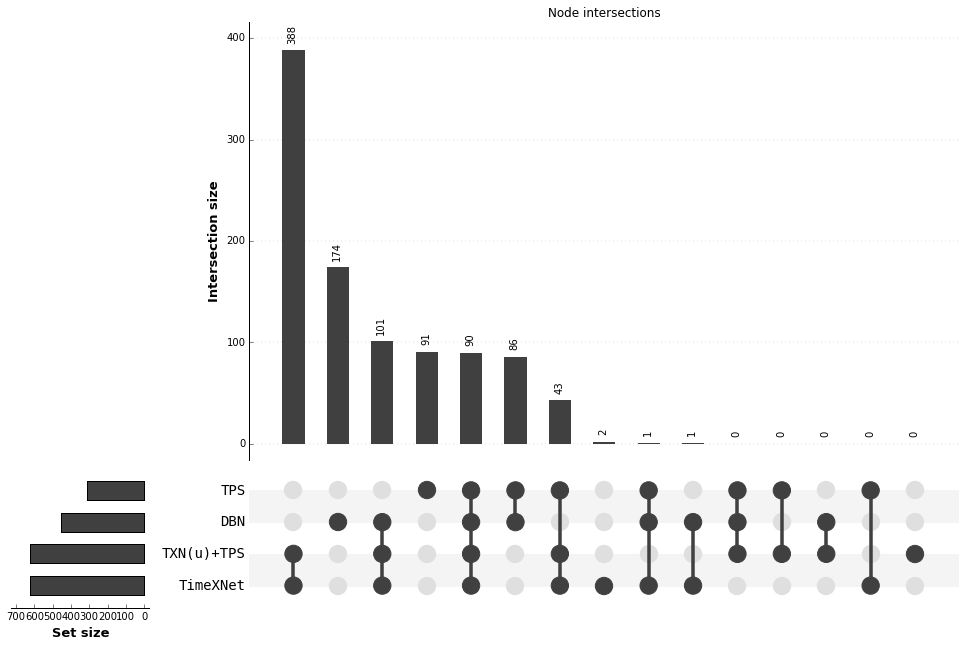

In [12]:
pyu.plot({'TPS':tps_df, 'TimeXNet':txn_df, 'DBN':dbn_thresh_df, 'TXN(u)+TPS':txn_tps_df});
title('Edge intersections');

pyu.plot({'TPS':tps_node_df, 'TimeXNet':txn_node_df, 'DBN':dbn_thresh_node_df, 'TXN(u)+TPS':txn_tps_node_df});
title('Node intersections');

## Compare the TPS, TimeXNet, DBN, and mass spectrometry nodes with the EGFR reference pathways
Ignore the TimeXNet+TPS networks.  200 reference pathway nodes (including a few non-protein nodes) are not in the mass spec data or any predicted network.  TimeXNet predicts the most nodes so it is not necessarily surprising that it contains the most unique EGFR reference pathway members.  However, it does have a greater fraction of predicted nodes in the EGFR pathway than TPS, but TPS has a greater fraction than the DBN.

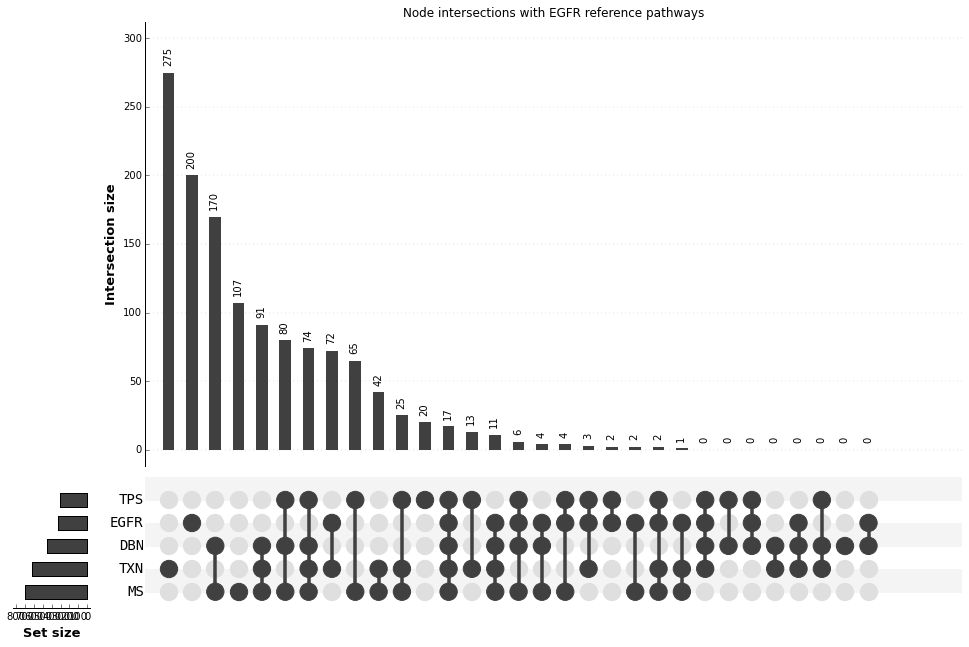

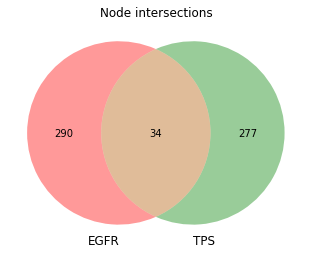

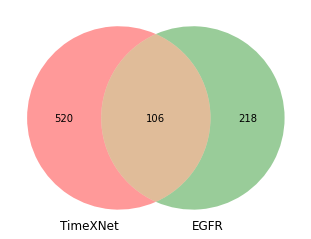

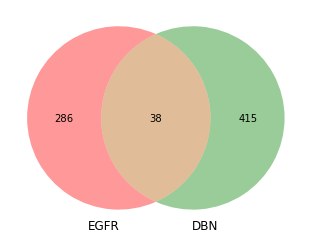

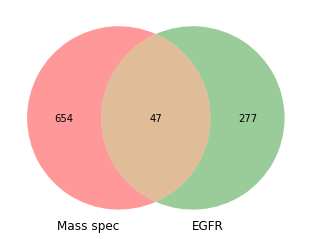

In [13]:
pyu.plot({'TPS':tps_node_df, 'TXN':txn_node_df, 'DBN':dbn_thresh_node_df, 'MS':ms_node_df, 'EGFR':gs_df});
title('Node intersections with EGFR reference pathways');

figure();
title('Node intersections');
venn2_unweighted(*venn_wrapper({'TPS':tps_node_df, 'EGFR':gs_df}, 'Nodes'))
show()

figure();
venn2_unweighted(*venn_wrapper({'TimeXNet':txn_node_df, 'EGFR':gs_df}, 'Nodes'))
show()

figure();
venn2_unweighted(*venn_wrapper({'DBN':dbn_thresh_node_df, 'EGFR':gs_df}, 'Nodes'))
show()

figure();
venn2_unweighted(*venn_wrapper({'Mass spec':ms_node_df, 'EGFR':gs_df}, 'Nodes'))
show()